# Week 11 - Introduction to Modeling, part 2

# 1. Lesson - No lesson this week

# 2. Weekly graph question

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

The book names one of Vonnegut's rules as "keep it simple" and another as "have the guts to cut."  Here is some data from the previous week's lesson.  If you had to cut one of the two plots below, which would it be?  Which seems more interesting or important?  Explain.  (Should "amount of training data used" or "number of estimators" be on the x-axis.)

In [2]:
np.random.seed(0)
num_points = 10000
feature_1a = np.random.random(size = num_points) * 3
feature_2a = np.random.random(size = num_points) * 3
feature_3a = np.random.random(size = num_points) * 3
train_target = (feature_1a - 2 * feature_2a) * feature_3a + np.random.normal(size = num_points)
feature_1b = np.random.random(size = num_points) * 3
feature_2b = np.random.random(size = num_points) * 3
feature_3b = np.random.random(size = num_points) * 3
test_target = (feature_1b - 2 * feature_2b) * feature_3b + np.random.normal(size = num_points)
train_df = pd.DataFrame({"f1": feature_1a, "f2": feature_2a, "f3": feature_3a})
test_df = pd.DataFrame({"f1": feature_1b, "f2": feature_2b, "f3": feature_3b})
rf = RandomForestRegressor()
rf.fit(train_df.values, train_target)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [3]:
rmse_lst = list()
rf = RandomForestRegressor()
for x in range(round(num_points / 20), num_points, round(num_points / 20)):
    rf.fit(train_df.values[0:x,:], train_target[0:x])
    rmse_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

import matplotlib.pyplot as plt

Text(0, 0.5, 'Loss function')

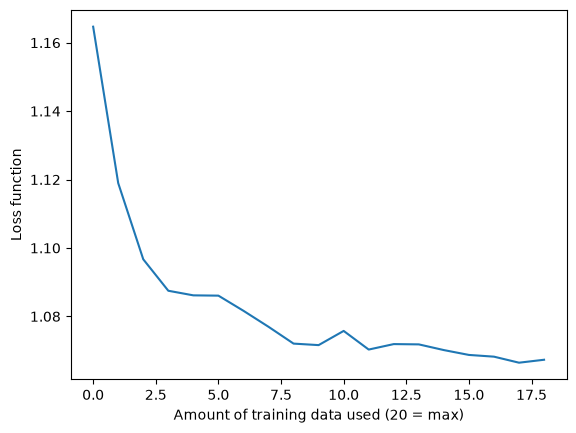

In [4]:
plt.plot(rmse_lst)
plt.xlabel("Amount of training data used (20 = max)")
plt.ylabel("Loss function")

In [5]:
num_trees_lst = list()
for n_estimators in range(1, 100, 3):
    rf = RandomForestRegressor(n_estimators = n_estimators)
    rf.fit(train_df.values, train_target)
    num_trees_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

Text(0, 0.5, 'Loss function')

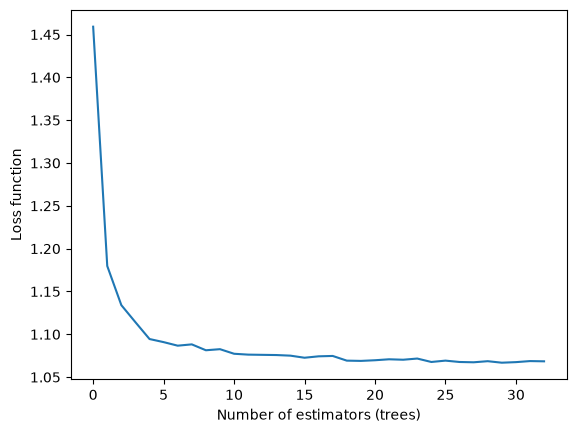

In [6]:
plt.plot(num_trees_lst)
plt.xlabel("Number of estimators (trees)")
plt.ylabel("Loss function")

If I had to cut one of the two graphs, I would remove the graph showing the number of estimators and keep the graph showing the amount of training data used. The training-data graph seems more useful because it shows how the model improves as it is given more information to learn from. The RMSE decreases as the amount of training data increases and then begins to level off. This gives a clearer picture of how much additional data is helping the model. The number-of-estimators graph is less interesting because once the random forest has enough trees, adding more trees does not seem to improve the model very much. Since the goal is to keep the message simple and remove information that does not add much value, I think the training-data graph is the stronger one to keep.

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:

* Implement a random forest model.
* Perform cross-validation.
* Tune hyperparameters.
* Evaluate a performance metric.

If you like, you can try other types of models, too (beyond linear regression and random forest) although you will have many opportunities to do that next semester.

In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [8]:
print(df.shape)
print(df["Diabetes_012"].value_counts())
print(df["Diabetes_012"].value_counts(normalize=True))

(253680, 22)
Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64
Diabetes_012
0.0    0.842412
2.0    0.139333
1.0    0.018255
Name: proportion, dtype: float64


In [9]:
# Use a stratified split so the three diabetes categories remain proportionally represented

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (202944, 21)
Test shape: (50736, 21)


In [10]:
# Building the randon forest 
# Using RandomForestClassifier because my dataset is categorical 

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=16,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",16
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider

In [11]:
# Evaluate the model 
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.762712866603595
Macro F1: 0.4441806771757258

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.80      0.86     42741
           1       0.03      0.02      0.02       926
           2       0.35      0.65      0.45      7069

    accuracy                           0.76     50736
   macro avg       0.43      0.49      0.44     50736
weighted avg       0.83      0.76      0.78     50736


Confusion Matrix:
[[34079   509  8153]
 [  449    18   459]
 [ 2340   129  4600]]


The random forest achieved an accuracy of about 76%, but the results show why accuracy should not be used by itself for this dataset. The model performed best for participants without diabetes and was also able to identify many participants with diabetes. However, it had difficulty identifying the prediabetes group. This is likely related to the strong class imbalance in the dataset because prediabetes represents less than 2% of the observations.
The macro F1 score was about 0.44, which is much lower than the overall accuracy. This suggests that performance was not equally strong across all three classes. The result reinforces the importance of looking at precision, recall, F1-score, and the confusion matrix when evaluating an imbalanced dataset.

In [12]:
# Examining most useful varables for the random forest 
feature_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance.head(10))

BMI          0.155560
Age          0.125765
GenHlth      0.099099
Income       0.084084
PhysHlth     0.075646
MentHlth     0.065311
HighBP       0.062963
Education    0.057755
HighChol     0.040852
Smoker       0.029012
dtype: float64


The random forest feature-importance results were generally consistent with the patterns I found during the earlier exploratory analysis. BMI was the most important feature, followed by age, general health, income, physical health, and high blood pressure. This was interesting because several of these variables had already shown noticeable relationships with diabetes status during the univariate and bivariate analysis. For example, participants with diabetes had higher BMI, poorer general health, higher rates of high blood pressure, and tended to be older. The random forest results provide additional evidence that diabetes status is related to several health and socioeconomic factors working together rather than one single predictor.

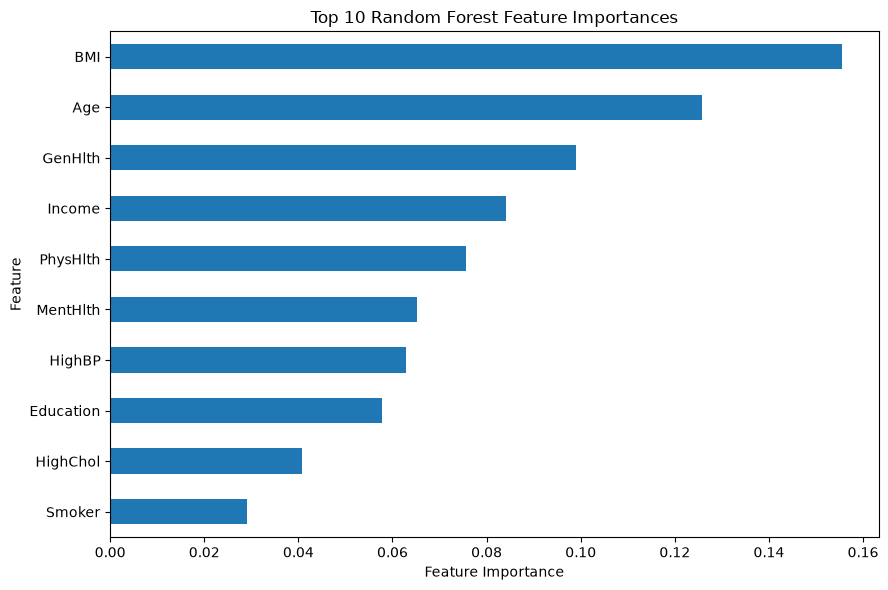

In [13]:
# Plot the feature
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values()

plt.figure(figsize=(9, 6))

top_features.plot(kind="barh")

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [14]:
# Cross-Validation
# Using StratifieldFold due to imbalance dataset 
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)
print("Average Macro F1:", cv_scores.mean())

Cross-validation scores: [0.44708519 0.44604155 0.44868134]
Average Macro F1: 0.44726935582639066


I used stratified three-fold cross-validation because the diabetes categories are highly imbalanced. Stratification helps preserve approximately the same proportion of each diabetes category in every fold.
The macro F1 scores were approximately 0.446, 0.448, and 0.447, with an average of about 0.447. The scores were very similar across the three folds, suggesting that the model's performance is fairly stable across different portions of the dataset. However, the general macro F1 score remained moderate because the model continued to have difficulty predicting the small prediabetes class.

In [15]:
# Using RandomizedSearchCV due to the size of the dataset 

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_dist = {
    "n_estimators": [60, 100, 140],
    "max_depth": [10, 14, 18, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_search = RandomForestClassifier(
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf_search,
    param_distributions=param_dist,
    n_iter=5,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

In [16]:
# Tuning phase 

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=60000,
    random_state=42,
    stratify=y_train
)

random_search.fit(X_tune, y_tune)

print("Best parameters:")
print(random_search.best_params_)

print("Best CV macro F1:")
print(random_search.best_score_)

Best parameters:
{'n_estimators': 60, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}
Best CV macro F1:
0.4475496406872182


In [17]:
# Training the tuned model and the full training data

best_rf = RandomForestClassifier(
    n_estimators=60,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features="sqrt",
    max_depth=None,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

best_pred = best_rf.predict(X_test)

print(
    classification_report(
        y_test,
        best_pred
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        best_pred,
        average="macro"
    )
)

              precision    recall  f1-score   support

           0       0.91      0.84      0.88     42741
           1       0.01      0.00      0.00       926
           2       0.37      0.58      0.46      7069

    accuracy                           0.79     50736
   macro avg       0.43      0.48      0.45     50736
weighted avg       0.82      0.79      0.80     50736

Macro F1: 0.44563987048887377


The Week 11 analysis showed that random forest modeling can identify meaningful patterns in the Diabetes Health Indicators dataset. Several of the most important features, including BMI, age, general health, income, and high blood pressure, were also variables that stood out during my earlier exploratory analysis.
The model performed reasonably well when distinguishing participants with no diabetes from those with diabetes. However, it had substantial difficulty predicting prediabetes. This appears to be related to the strong class imbalance because the prediabetes group accounts for less than 2% of the dataset.

Cross-validation produced similar macro F1 scores across the different folds, which suggests that the results were relatively stable. Hyperparameter tuning produced some improvement, but it did not completely solve the problem of identifying the minority prediabetes class.
In conclusion, the results suggest that random forest is useful for identifying important predictors and modeling nonlinear relationships in this dataset, but additional approaches may be needed to improve performance for the minority class.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in chapter seven (p. 165-185) of the Storytelling With Data book as best you can. You do not have to get the exact data values right, just the overall look and feel.

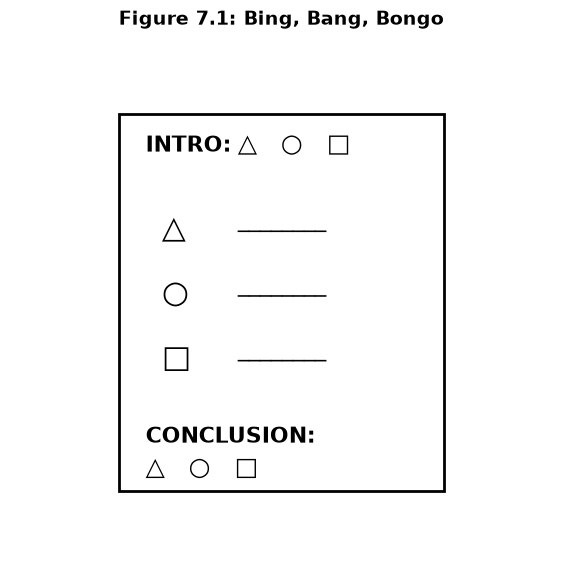

In [20]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(7, 7))

# Remove axes
ax.axis("off")

# Main outline
box = Rectangle((0.2, 0.15), 0.6, 0.7, fill=False, linewidth=2)
ax.add_patch(box)

# Intro section
ax.text(0.25, 0.78, "INTRO:", fontsize=16, fontweight="bold")

# Simple symbols for intro
ax.text(0.42, 0.78, "△   ○   □", fontsize=18)

# Middle content
ax.text(0.28, 0.62, "△", fontsize=22)
ax.text(0.42, 0.62, "────────", fontsize=14)

ax.text(0.28, 0.50, "○", fontsize=22)
ax.text(0.42, 0.50, "────────", fontsize=14)

ax.text(0.28, 0.38, "□", fontsize=22)
ax.text(0.42, 0.38, "────────", fontsize=14)

# Conclusion section
ax.text(0.25, 0.24, "CONCLUSION:", fontsize=16, fontweight="bold")
ax.text(0.25, 0.18, "△   ○   □", fontsize=18)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.title(
    "Figure 7.1: Bing, Bang, Bongo",
    fontsize=14,
    fontweight="bold"
)

plt.show()

I chose to recreate Figure 7.1, “Bing, Bang, Bongo,” from page 181 of Storytelling With Data. The figure shows a simple way to organize a presentation or report by first telling the audience what will be discussed, then presenting the main information, and finally summarizing the key points. I chose this figure because it is simple and easy to understand. The main idea is that repetition can help the audience follow the message and remember the most important information. I also think this approach connects well with data presentations because it gives the audience a clear beginning, middle, and ending instead of just showing information without structure.